In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
import contextily as ctx  
from pypalettes import load_cmap
from matplotlib.colors import LogNorm

In [2]:
gdf = gpd.read_file("geojson-v2/lisbon-mobile-towers.geojson")

In [3]:
gdf.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [4]:
gdf["man_made"].value_counts(dropna=False)

man_made
antenna         1547
mast            1293
tower              8
None               1
utility_pole       1
Name: count, dtype: int64

In [5]:
# Filter for antennas and project to metres
gdf = gdf[gdf["man_made"] == "antenna"].copy()
gdf = gdf.to_crs("EPSG:3763")

In [6]:
# DBSCAN clustering
eps = 1000
min_samples = 3

coordinates = list(zip(gdf.geometry.x, gdf.geometry.y))

dbscan = DBSCAN(eps=eps, min_samples=min_samples)

gdf["cluster"] = dbscan.fit_predict(coordinates)

# Clusters vs noise
clusters = gdf[gdf["cluster"] != -1].copy()
isolated = gdf[gdf["cluster"] == -1].copy()

In [7]:
# Cluster summary
clusters["x"] = clusters.geometry.x
clusters["y"] = clusters.geometry.y

cluster_summary = (clusters.groupby("cluster").agg(
    x=("x", "mean"), y=("y", "mean"), count=("cluster", "size")).reset_index())

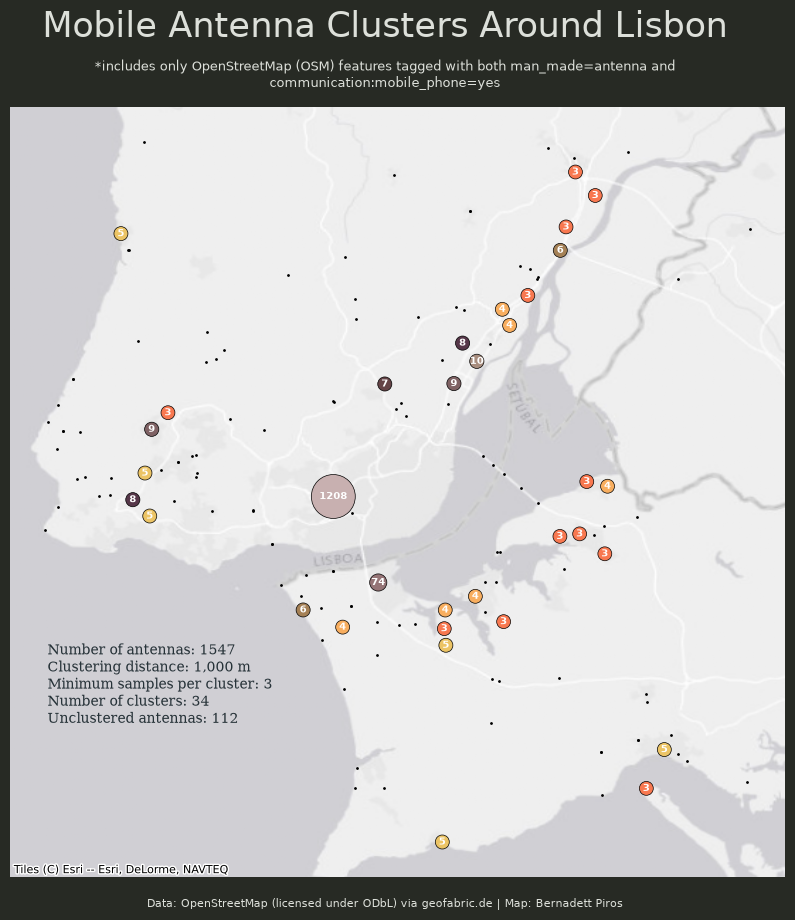

In [8]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#272a24")

# Noise
ax.scatter(isolated.geometry.x, isolated.geometry.y, s=1, color="black")

# Sizes
min_s = 100
max_s = 1000
s = cluster_summary["count"]
s = min_s + (s - s.min()) * (max_s - min_s) / (s.max() - s.min())


cmap = load_cmap("blaziken", cmap_type="continuous")

# Clusters
ax.scatter(cluster_summary["x"], cluster_summary["y"], s=s, c=cluster_summary["count"], 
           cmap=cmap, norm=LogNorm(), ec="black", lw=0.5)

# Cluster labels
for i, row in cluster_summary.iterrows():    
        ax.text(row["x"], row["y"], str(int(row["count"])), color="white", size=7,  weight="bold",
                ha="center", va="center")     

# Inset ax
inset_ax = fig.add_axes([0.15, 0.25, 0.25, 0.1]) 
inset_ax.patch.set_alpha(0)

# Clustering statistics
stats = (
    f"Number of antennas: {len(gdf)}\n"
    f"Clustering distance: {eps:,} m\n"
    f"Minimum samples per cluster: {min_samples}\n"
    f"Number of clusters: {len(cluster_summary)}\n"
    f"Unclustered antennas: {len(isolated)}"
)

# Text to inset axis
inset_ax.text(0.05, 0.95, stats, color="#263238", fontsize=10, fontfamily="serif",
              va="top", transform=inset_ax.transAxes) 

inset_ax.axis("off")

# Add basemap
ctx.add_basemap(ax=ax, crs=clusters.crs, source=ctx.providers.Esri.WorldGrayCanvas, zoom="auto")
   
ax.axis("off")

fig.text(0.5, 0.95,
         "Mobile Antenna Clusters Around Lisbon",    
         color="#dde0da", fontsize=25, ha="center")

fig.text(0.5, 0.9,
         "*includes only OpenStreetMap (OSM) features tagged with both man_made=antenna and\ncommunication:mobile_phone=yes",
         color="#dde0da", fontsize=9, ha="center")

fig.text(0.5, 0.08,    
         "Data: OpenStreetMap (licensed under ODbL) via geofabric.de | Map: Bernadett Piros",   
         color="#dde0da", fontsize=8, ha="center")

plt.show()

fig.savefig("antenna_clusters.png", bbox_inches="tight", pad_inches=0.2) 